# DATA 255 - Lab 2: Super Resolution / Image Restoration
### Spring 2026 | San Jose State University
---
**Architecture:** LightResUNet with Hybrid Output (~4M params)

**Loss:** L1 + Sobel + VGG Perceptual

**Scheduler:** OneCycleLR

**Drive Folder:** Deep Learning Lab2

## Cell 1: Install Required Packages

In [1]:
# Install all required packages
!pip install onnx onnxscript onnxruntime -q
print('All packages installed! ')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.6/17.6 MB 130.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.1/689.1 kB 52.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 128.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 164.1/164.1 kB 19.8 MB/s eta 0:00:00
All packages installed! 


## Cell 2: Mount Google Drive

In [2]:
from google.colab import drive
drive.mount('/content/drive')
print('Drive mounted!')

Mounted at /content/drive
Drive mounted!


## Cell 3: Check GPU + Set Seeds

In [3]:
import torch
import numpy as np
import random
import os

# Reproducibility
SEED = 42
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
np.random.seed(SEED)
random.seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark     = False

print(f'PyTorch version : {torch.__version__}')
print(f'GPU available   : {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU name        : {torch.cuda.get_device_name(0)}')
    print(f'GPU memory      : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device    : {DEVICE}')
print(f'Seed            : {SEED}')

PyTorch version : 2.10.0+cu128
GPU available   : True
GPU name        : NVIDIA A100-SXM4-40GB
GPU memory      : 42.4 GB
Using device    : cuda
Seed            : 42


## Cell 4: Unzip ALL 12 Dataset Files
> Drive folder: Deep Learning Lab2

In [4]:
import zipfile
import os
import time

# Updated folder name
DRIVE_PATH = '/content/drive/MyDrive/Deep Learning Lab2'
DATA_ROOT  = '/content/data'
os.makedirs(DATA_ROOT, exist_ok=True)

zip_files = {
    'LR_train' : f'{DRIVE_PATH}/LR_train.zip',
    'LR_train1': f'{DRIVE_PATH}/LR_train1.zip',
    'LR_train2': f'{DRIVE_PATH}/LR_train2.zip',
    'LR_train3': f'{DRIVE_PATH}/LR_train3.zip',
    'LR_train4': f'{DRIVE_PATH}/LR_train4.zip',
    'HR_train' : f'{DRIVE_PATH}/HR_train.zip',
    'HR_train1': f'{DRIVE_PATH}/HR_train1.zip',
    'HR_train2': f'{DRIVE_PATH}/HR_train2.zip',
    'HR_train3': f'{DRIVE_PATH}/HR_train3.zip',
    'HR_train4': f'{DRIVE_PATH}/HR_train4.zip',
    'LR_val'   : f'{DRIVE_PATH}/LR_val.zip',
    'HR_val'   : f'{DRIVE_PATH}/HR_val.zip',
}

for name, zip_path in zip_files.items():
    extract_path = os.path.join(DATA_ROOT, name)
    if os.path.exists(extract_path):
        print(f'Already extracted: {name} ')
        continue
    for attempt in range(3):
        try:
            print(f'Extracting {name}... (attempt {attempt+1})')
            with zipfile.ZipFile(zip_path, 'r') as zf:
                zf.extractall(extract_path)
            print(f'  Done -> {extract_path} ')
            break
        except OSError as e:
            print(f'  Error: {e} - Remounting Drive...')
            time.sleep(3)
            from google.colab import drive
            drive.mount('/content/drive', force_remount=True)
            time.sleep(5)

print('\nAll zips extracted!')

Extracting LR_train... (attempt 1)
  Done -> /content/data/LR_train 
Extracting LR_train1... (attempt 1)
  Done -> /content/data/LR_train1 
Extracting LR_train2... (attempt 1)
  Done -> /content/data/LR_train2 
Extracting LR_train3... (attempt 1)
  Done -> /content/data/LR_train3 
Extracting LR_train4... (attempt 1)
  Done -> /content/data/LR_train4 
Extracting HR_train... (attempt 1)
  Error: [Errno 107] Transport endpoint is not connected - Remounting Drive...
Mounted at /content/drive
Extracting HR_train... (attempt 2)
  Done -> /content/data/HR_train 
Extracting HR_train1... (attempt 1)
  Done -> /content/data/HR_train1 
Extracting HR_train2... (attempt 1)
  Done -> /content/data/HR_train2 
Extracting HR_train3... (attempt 1)
  Done -> /content/data/HR_train3 
Extracting HR_train4... (attempt 1)
  Done -> /content/data/HR_train4 
Extracting LR_val... (attempt 1)
  Done -> /content/data/LR_val 
Extracting HR_val... (attempt 1)
  Done -> /content/data/HR_val 

All zips extracted!


## Cell 5: Verify Dataset

In [5]:
from glob import glob

def get_images(folder):
    return sorted([
        f for f in glob(os.path.join(folder, '**', '*'), recursive=True)
        if f.lower().endswith(('.png', '.jpg', '.jpeg'))
    ])

lr_train_dirs = [
    f'{DATA_ROOT}/LR_train',  f'{DATA_ROOT}/LR_train1',
    f'{DATA_ROOT}/LR_train2', f'{DATA_ROOT}/LR_train3',
    f'{DATA_ROOT}/LR_train4'
]
hr_train_dirs = [
    f'{DATA_ROOT}/HR_train',  f'{DATA_ROOT}/HR_train1',
    f'{DATA_ROOT}/HR_train2', f'{DATA_ROOT}/HR_train3',
    f'{DATA_ROOT}/HR_train4'
]

total_lr = sum(len(get_images(d)) for d in lr_train_dirs)
total_hr = sum(len(get_images(d)) for d in hr_train_dirs)

print(f'LR Train images  : {total_lr}')
print(f'HR Train images  : {total_hr}')
print(f'LR Val images    : {len(get_images(f"{DATA_ROOT}/LR_val"))}')
print(f'HR Val images    : {len(get_images(f"{DATA_ROOT}/HR_val"))}')
assert total_lr == total_hr, 'LR/HR mismatch!'
print(f'\nTotal train pairs: {total_lr} ')

LR Train images  : 3325
HR Train images  : 3325
LR Val images    : 100
HR Val images    : 100

Total train pairs: 3325 


## Cell 6: Imports

In [6]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, ConcatDataset
import torchvision.transforms as transforms
import torchvision.transforms.functional as TF
import torchvision.models as models
from PIL import Image
import numpy as np
import os
import random
import math
import shutil
import matplotlib.pyplot as plt
from glob import glob

print('All imports successful!')

All imports successful!


## Cell 7: Dataset Class

In [7]:
class SRDataset(Dataset):
    """
    Image Restoration Dataset.
    Loads paired LR (degraded) and HR (clean) images.
    Both 256x256x3. Normalization [0,1].
    """
    def __init__(self, lr_dir, hr_dir, augment=False):
        self.augment  = augment
        self.lr_files = sorted([
            f for f in glob(os.path.join(lr_dir, '**', '*'), recursive=True)
            if f.lower().endswith(('.png', '.jpg', '.jpeg'))
        ])
        self.hr_files = sorted([
            f for f in glob(os.path.join(hr_dir, '**', '*'), recursive=True)
            if f.lower().endswith(('.png', '.jpg', '.jpeg'))
        ])
        assert len(self.lr_files) == len(self.hr_files), \
            f'Mismatch: {len(self.lr_files)} LR vs {len(self.hr_files)} HR'

        self.transform = transforms.Compose([
            transforms.Resize((256, 256), Image.BILINEAR),
            transforms.ToTensor()
        ])

    def __len__(self):
        return len(self.lr_files)

    def __getitem__(self, idx):
        lr_img = Image.open(self.lr_files[idx]).convert('RGB')
        hr_img = Image.open(self.hr_files[idx]).convert('RGB')

        if self.augment:
            if random.random() > 0.5:
                lr_img = TF.hflip(lr_img)
                hr_img = TF.hflip(hr_img)
            if random.random() > 0.5:
                lr_img = TF.vflip(lr_img)
                hr_img = TF.vflip(hr_img)
            if random.random() > 0.5:
                angle  = random.choice([90, 180, 270])
                lr_img = TF.rotate(lr_img, angle)
                hr_img = TF.rotate(hr_img, angle)
            if random.random() > 0.5:
                factor = random.uniform(0.8, 1.2)
                lr_img = TF.adjust_brightness(lr_img, factor)
                hr_img = TF.adjust_brightness(hr_img, factor)
            if random.random() > 0.5:
                factor = random.uniform(0.8, 1.2)
                lr_img = TF.adjust_contrast(lr_img, factor)
                hr_img = TF.adjust_contrast(hr_img, factor)

        return self.transform(lr_img), self.transform(hr_img)

print('SRDataset ready!')

SRDataset ready!


## Cell 8: Load ALL Training Data

In [8]:
train_datasets = []

for lr_dir, hr_dir in zip(lr_train_dirs, hr_train_dirs):
    ds = SRDataset(lr_dir, hr_dir, augment=True)
    train_datasets.append(ds)
    print(f'Loaded: {os.path.basename(lr_dir)} -> {len(ds)} pairs')

full_train_dataset = ConcatDataset(train_datasets)

val_dataset = SRDataset(
    f'{DATA_ROOT}/LR_val',
    f'{DATA_ROOT}/HR_val',
    augment=False
)

print(f'\nTotal training pairs : {len(full_train_dataset)}')
print(f'Total val pairs      : {len(val_dataset)}')

Loaded: LR_train -> 289 pairs
Loaded: LR_train1 -> 663 pairs
Loaded: LR_train2 -> 782 pairs
Loaded: LR_train3 -> 810 pairs
Loaded: LR_train4 -> 781 pairs

Total training pairs : 3325
Total val pairs      : 100


## Cell 9: Hyperparameters & DataLoaders

In [9]:
BATCH_SIZE    = 16
LEARNING_RATE = 1e-3
NUM_EPOCHS    = 100
NUM_WORKERS   = 2
SAVE_EVERY    = 10

# Updated Drive folder name
SAVE_DIR = '/content/drive/MyDrive/Deep Learning Lab2/outputs'
os.makedirs(SAVE_DIR, exist_ok=True)

train_loader = DataLoader(
    full_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print(f'Train batches : {len(train_loader)}')
print(f'Val batches   : {len(val_loader)}')
print(f'Batch size    : {BATCH_SIZE}')
print(f'Epochs        : {NUM_EPOCHS}')
print(f'Learning rate : {LEARNING_RATE}')
print(f'Save dir      : {SAVE_DIR}')

Train batches : 208
Val batches   : 7
Batch size    : 16
Epochs        : 100
Learning rate : 0.001
Save dir      : /content/drive/MyDrive/Deep Learning Lab2/outputs


## Cell 10: Custom Model — LightResUNet with Hybrid Output
> Unique architecture: ResBlocks + Dilated Bottleneck + Channel Attention
> Hybrid Output: learned alpha blend of direct + residual predictions

In [10]:
# ── Channel Attention ─────────────────────────────────────────────────────────
class ChannelAttention(nn.Module):
    def __init__(self, channels, reduction=8):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Linear(channels, max(channels // reduction, 4), bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(max(channels // reduction, 4), channels, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        b, c, _, _ = x.shape
        y = self.avg_pool(x).view(b, c)
        y = self.fc(y).view(b, c, 1, 1)
        return x * y


# ── Residual Block ────────────────────────────────────────────────────────────
class ResBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(channels, channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(channels, channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(channels)
        )
        self.ca   = ChannelAttention(channels)
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        out = self.block(x)
        out = self.ca(out)
        return self.relu(out + x)


# ── Dilated Bottleneck ────────────────────────────────────────────────────────
class DilatedBottleneck(nn.Module):
    def __init__(self, channels):
        super().__init__()
        mid = channels // 4
        self.d1 = nn.Conv2d(channels, mid, 3, padding=1,  dilation=1, bias=False)
        self.d2 = nn.Conv2d(channels, mid, 3, padding=2,  dilation=2, bias=False)
        self.d4 = nn.Conv2d(channels, mid, 3, padding=4,  dilation=4, bias=False)
        self.d8 = nn.Conv2d(channels, mid, 3, padding=8,  dilation=8, bias=False)
        self.fuse = nn.Sequential(
            nn.Conv2d(mid * 4, channels, 1, bias=False),
            nn.BatchNorm2d(channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        out = torch.cat([
            torch.relu(self.d1(x)),
            torch.relu(self.d2(x)),
            torch.relu(self.d4(x)),
            torch.relu(self.d8(x))
        ], dim=1)
        return self.fuse(out) + x


# ── Encoder Block ─────────────────────────────────────────────────────────────
class EncoderBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )
        self.res  = ResBlock(out_ch)
        self.pool = nn.MaxPool2d(2, 2)

    def forward(self, x):
        x    = self.conv(x)
        skip = self.res(x)
        down = self.pool(skip)
        return skip, down


# ── Decoder Block ─────────────────────────────────────────────────────────────
class DecoderBlock(nn.Module):
    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_ch, out_ch, 2, stride=2, bias=False)
        self.conv = nn.Sequential(
            nn.Conv2d(out_ch + skip_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )
        self.res = ResBlock(out_ch)

    def forward(self, x, skip):
        x = self.up(x)
        x = torch.cat([x, skip], dim=1)
        x = self.conv(x)
        return self.res(x)


# ── Main Model: LightResUNet with Hybrid Output ───────────────────────────────
class LightResUNet(nn.Module):
    """
    Lightweight Residual U-Net for Image Restoration.
    Input : [B, 3, 256, 256] degraded LR image
    Output: [B, 3, 256, 256] restored HR image

    Hybrid output:
    - Direct path: predicts clean image directly
    - Residual path: predicts LR + correction
    - Alpha: learned blend of both paths
    """
    def __init__(self, base_ch=16):
        super().__init__()

        # Encoder
        self.enc1 = EncoderBlock(3,         base_ch)    # 256->128
        self.enc2 = EncoderBlock(base_ch,   base_ch*2)  # 128->64
        self.enc3 = EncoderBlock(base_ch*2, base_ch*4)  # 64->32
        self.enc4 = EncoderBlock(base_ch*4, base_ch*8)  # 32->16

        # Bottleneck
        self.bottleneck = nn.Sequential(
            nn.Conv2d(base_ch*8,  base_ch*16, 3, padding=1, bias=False),
            nn.BatchNorm2d(base_ch*16),
            nn.ReLU(inplace=True),
            DilatedBottleneck(base_ch*16),
            ResBlock(base_ch*16),
            nn.Conv2d(base_ch*16, base_ch*8,  3, padding=1, bias=False),
            nn.BatchNorm2d(base_ch*8),
            nn.ReLU(inplace=True)
        )

        # Decoder
        self.dec4 = DecoderBlock(base_ch*8, base_ch*8, base_ch*4)
        self.dec3 = DecoderBlock(base_ch*4, base_ch*4, base_ch*2)
        self.dec2 = DecoderBlock(base_ch*2, base_ch*2, base_ch)
        self.dec1 = DecoderBlock(base_ch,   base_ch,   base_ch)

        # Hybrid output heads
        self.out_direct   = nn.Conv2d(base_ch, 3, 3, padding=1)  # direct prediction
        self.out_residual = nn.Conv2d(base_ch, 3, 3, padding=1)  # residual correction
        self.out_alpha    = nn.Sequential(                         # blend weight
            nn.Conv2d(base_ch, 1, 3, padding=1),
            nn.Sigmoid()
        )

        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x):
        lr_input = x

        # Encoder
        s1, x = self.enc1(x)
        s2, x = self.enc2(x)
        s3, x = self.enc3(x)
        s4, x = self.enc4(x)

        # Bottleneck
        x = self.bottleneck(x)

        # Decoder
        x = self.dec4(x, s4)
        x = self.dec3(x, s3)
        x = self.dec2(x, s2)
        x = self.dec1(x, s1)

        # Hybrid output
        direct   = torch.sigmoid(self.out_direct(x))
        residual = torch.clamp(lr_input + self.out_residual(x), 0, 1)
        alpha    = self.out_alpha(x)

        return torch.clamp(alpha * direct + (1 - alpha) * residual, 0, 1)


# Build model
model = LightResUNet(base_ch=16).to(DEVICE)

# Test shape
dummy = torch.randn(1, 3, 256, 256).to(DEVICE)
with torch.no_grad():
    out = model(dummy)

print(f'Input  shape     : {dummy.shape}')
print(f'Output shape     : {out.shape}')

total     = sum(p.numel() for p in model.parameters())
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total params     : {total:,}')
print(f'Trainable params : {trainable:,}')
print(f'NPU friendly     : {" Yes" if total < 10_000_000 else "⚠️ Check"}')

Input  shape     : torch.Size([1, 3, 256, 256])
Output shape     : torch.Size([1, 3, 256, 256])
Total params     : 3,237,831
Trainable params : 3,237,831
NPU friendly     :  Yes


## Cell 11: Test ONNX Export Early
> Professor Tip 1: Always test before training!

In [11]:
import onnx

TEST_ONNX   = '/content/test_export.onnx'
model.eval()
dummy_input = torch.randn(1, 3, 256, 256).to(DEVICE)

try:
    torch.onnx.export(
        model,
        dummy_input,
        TEST_ONNX,
        export_params=True,
        opset_version=11,
        do_constant_folding=True,
        input_names=['image'],
        output_names=['predictions'],
        dynamic_axes={
            'image'      : {0: 'batch_size'},
            'predictions': {0: 'batch_size'}
        },
        verbose=False
    )
    # Merge into single file
    onnx_model = onnx.load(TEST_ONNX)
    onnx.save_model(onnx_model, TEST_ONNX, save_as_external_data=False)
    onnx.checker.check_model(onnx.load(TEST_ONNX))
    size_mb = os.path.getsize(TEST_ONNX) / 1e6
    print(f'ONNX test export  : Success')
    print(f'Size              : {size_mb:.1f} MB')
    print(f'Single file       : {" Yes" if size_mb > 1 else " Still split"}')
    print(f'Safe to train!    : ')
except Exception as e:
    print(f'ONNX export FAILED: {e}')
    print('Fix model before training!')

/tmp/ipykernel_864/799327308.py:8: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(
W0404 19:37:51.339000 864 torch/onnx/_internal/exporter/_compat.py:125] Setting ONNX exporter to use operator set version 18 because the requested opset_version 11 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features
W0404 19:37:52.267000 864 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'input' from (input, boxes, output_size: 'Sequence[int]', spatial_scale: 'float' = 1.0, sampling_ratio: 'int' = -1, aligne

Applied 82 of general pattern rewrite rules.
ONNX test export  : Success
Size              : 13.2 MB
Single file       :  Yes
Safe to train!    : 


## Cell 12: Loss Functions
> L1 + Sobel Edge Loss + VGG Perceptual Loss

In [12]:
# ── Sobel Edge Loss ───────────────────────────────────────────────────────────
class SobelLoss(nn.Module):
    """
    Edge-aware loss using Sobel filters.
    Penalizes blurry edges → sharper output → better PSNR.
    """
    def __init__(self):
        super().__init__()
        kx = torch.tensor([[-1,0,1],[-2,0,2],[-1,0,1]], dtype=torch.float32)
        ky = torch.tensor([[-1,-2,-1],[0,0,0],[1,2,1]],  dtype=torch.float32)
        self.register_buffer('kx', kx.view(1,1,3,3).repeat(3,1,1,1))
        self.register_buffer('ky', ky.view(1,1,3,3).repeat(3,1,1,1))

    def forward(self, pred, target):
        pred_gx   = F.conv2d(pred,   self.kx, padding=1, groups=3)
        pred_gy   = F.conv2d(pred,   self.ky, padding=1, groups=3)
        target_gx = F.conv2d(target, self.kx, padding=1, groups=3)
        target_gy = F.conv2d(target, self.ky, padding=1, groups=3)
        return F.l1_loss(pred_gx, target_gx) + F.l1_loss(pred_gy, target_gy)


# ── VGG Perceptual Loss ───────────────────────────────────────────────────────
class VGGPerceptualLoss(nn.Module):
    """
    Perceptual loss using VGG16 features.
    Compares high-level features instead of pixels.
    Helps recover textures and fine details.
    """
    def __init__(self):
        super().__init__()
        vgg = models.vgg16(weights=models.VGG16_Weights.DEFAULT).features[:16]
        self.vgg = vgg.eval()
        for p in self.vgg.parameters():
            p.requires_grad = False

    def forward(self, pred, target):
        pred_f   = self.vgg(pred)
        target_f = self.vgg(target)
        return F.l1_loss(pred_f, target_f)


# ── Combined Loss ─────────────────────────────────────────────────────────────
class CombinedLoss(nn.Module):
    """
    L1 + Sobel + VGG loss combination.
    L1     : pixel accuracy
    Sobel  : edge sharpness
    VGG    : perceptual quality
    """
    def __init__(self, w_l1=1.0, w_sobel=0.1, w_vgg=0.1):
        super().__init__()
        self.w_l1    = w_l1
        self.w_sobel = w_sobel
        self.w_vgg   = w_vgg
        self.l1      = nn.L1Loss()
        self.sobel   = SobelLoss()
        self.vgg     = VGGPerceptualLoss()

    def forward(self, pred, target):
        l1_loss    = self.l1(pred, target)
        sobel_loss = self.sobel(pred, target)
        vgg_loss   = self.vgg(pred, target)
        return (self.w_l1    * l1_loss +
                self.w_sobel * sobel_loss +
                self.w_vgg   * vgg_loss)


# ── PSNR Metric ───────────────────────────────────────────────────────────────
def compute_psnr(pred, target):
    """
    Compute PSNR in dB. Images in [0,1].
    Higher = better. Target > 23 dB.
    """
    mse = torch.mean((pred.clamp(0,1) - target.clamp(0,1)) ** 2)
    if mse == 0:
        return float('inf')
    return 20 * math.log10(1.0 / math.sqrt(mse.item()))


print('Loss functions ready!')
print('L1 + Sobel + VGG Perceptual')

Loss functions ready!
L1 + Sobel + VGG Perceptual


## Cell 13: Optimizer & Scheduler
> OneCycleLR for better convergence

In [13]:
criterion = CombinedLoss(w_l1=1.0, w_sobel=0.1, w_vgg=0.1).to(DEVICE)

optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    betas=(0.9, 0.999),
    weight_decay=1e-5
)

# OneCycleLR: warmup then anneal
# Better convergence than ReduceLROnPlateau
scheduler = optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=LEARNING_RATE,
    steps_per_epoch=len(train_loader),
    epochs=NUM_EPOCHS,
    pct_start=0.3,
    anneal_strategy='cos'
)

print('Optimizer : Adam')
print('Scheduler : OneCycleLR')
print('Loss      : L1 + Sobel + VGG')

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:02<00:00, 245MB/s]


Optimizer : Adam
Scheduler : OneCycleLR
Loss      : L1 + Sobel + VGG


## Cell 14: Training Loop

In [14]:
train_losses = []
val_psnrs    = []
best_psnr    = 0.0

print('=' * 65)
print('Starting Training — LightResUNet v6')
print('L1 + Sobel + VGG | Hybrid Output | OneCycleLR')
print('=' * 65)

for epoch in range(1, NUM_EPOCHS + 1):

    # ── Training ──────────────────────────────────────────────────────────────
    model.train()
    epoch_loss = 0.0

    for lr_imgs, hr_imgs in train_loader:
        lr_imgs = lr_imgs.to(DEVICE)
        hr_imgs = hr_imgs.to(DEVICE)

        optimizer.zero_grad()
        pred = model(lr_imgs)
        loss = criterion(pred, hr_imgs)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        optimizer.step()
        scheduler.step()
        epoch_loss += loss.item()

    avg_train_loss = epoch_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    # ── Validation ────────────────────────────────────────────────────────────
    model.eval()
    total_psnr = 0.0

    with torch.no_grad():
        for lr_imgs, hr_imgs in val_loader:
            lr_imgs = lr_imgs.to(DEVICE)
            hr_imgs = hr_imgs.to(DEVICE)
            pred    = model(lr_imgs)
            for i in range(pred.shape[0]):
                total_psnr += compute_psnr(pred[i], hr_imgs[i])

    avg_psnr   = total_psnr / len(val_dataset)
    val_psnrs.append(avg_psnr)
    current_lr = optimizer.param_groups[0]['lr']

    print(f'Epoch [{epoch:03d}/{NUM_EPOCHS}] | '
          f'Loss: {avg_train_loss:.4f} | '
          f'Val PSNR: {avg_psnr:.2f} dB | '
          f'LR: {current_lr:.2e}')

    # ── Save best model ────────────────────────────────────────────────────────
    if avg_psnr > best_psnr:
        best_psnr = avg_psnr
        torch.save({
            'epoch'               : epoch,
            'model_state_dict'    : model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'best_psnr'           : best_psnr,
            'architecture'        : 'LightResUNet',
            'base_ch'             : 16
        }, os.path.join(SAVE_DIR, 'best_model.pth'))
        print(f'  --> New best! PSNR: {best_psnr:.2f} dB saved!')

    # ── Checkpoint every 10 epochs ─────────────────────────────────────────────
    if epoch % SAVE_EVERY == 0:
        torch.save({
            'epoch'           : epoch,
            'model_state_dict': model.state_dict(),
            'psnr'            : avg_psnr,
            'architecture'    : 'LightResUNet',
            'base_ch'         : 16
        }, os.path.join(SAVE_DIR, f'checkpoint_epoch_{epoch}.pth'))
        print(f'  --> Checkpoint saved at epoch {epoch}')

print('=' * 65)
print(f'Training complete! Best PSNR: {best_psnr:.2f} dB')
print('=' * 65)

Starting Training — LightResUNet v6
L1 + Sobel + VGG | Hybrid Output | OneCycleLR
Epoch [001/100] | Loss: 0.3906 | Val PSNR: 11.68 dB | LR: 4.26e-05
  --> New best! PSNR: 11.68 dB saved!
Epoch [002/100] | Loss: 0.2321 | Val PSNR: 16.23 dB | LR: 5.05e-05
  --> New best! PSNR: 16.23 dB saved!
Epoch [003/100] | Loss: 0.1862 | Val PSNR: 18.04 dB | LR: 6.35e-05
  --> New best! PSNR: 18.04 dB saved!
Epoch [004/100] | Loss: 0.1645 | Val PSNR: 18.85 dB | LR: 8.15e-05
  --> New best! PSNR: 18.85 dB saved!
Epoch [005/100] | Loss: 0.1559 | Val PSNR: 19.47 dB | LR: 1.04e-04
  --> New best! PSNR: 19.47 dB saved!
Epoch [006/100] | Loss: 0.1495 | Val PSNR: 19.78 dB | LR: 1.32e-04
  --> New best! PSNR: 19.78 dB saved!
Epoch [007/100] | Loss: 0.1445 | Val PSNR: 19.98 dB | LR: 1.63e-04
  --> New best! PSNR: 19.98 dB saved!
Epoch [008/100] | Loss: 0.1404 | Val PSNR: 20.25 dB | LR: 1.99e-04
  --> New best! PSNR: 20.25 dB saved!
Epoch [009/100] | Loss: 0.1382 | Val PSNR: 20.50 dB | LR: 2.38e-04
  --> New b

## Cell 15: Plot Training Curves

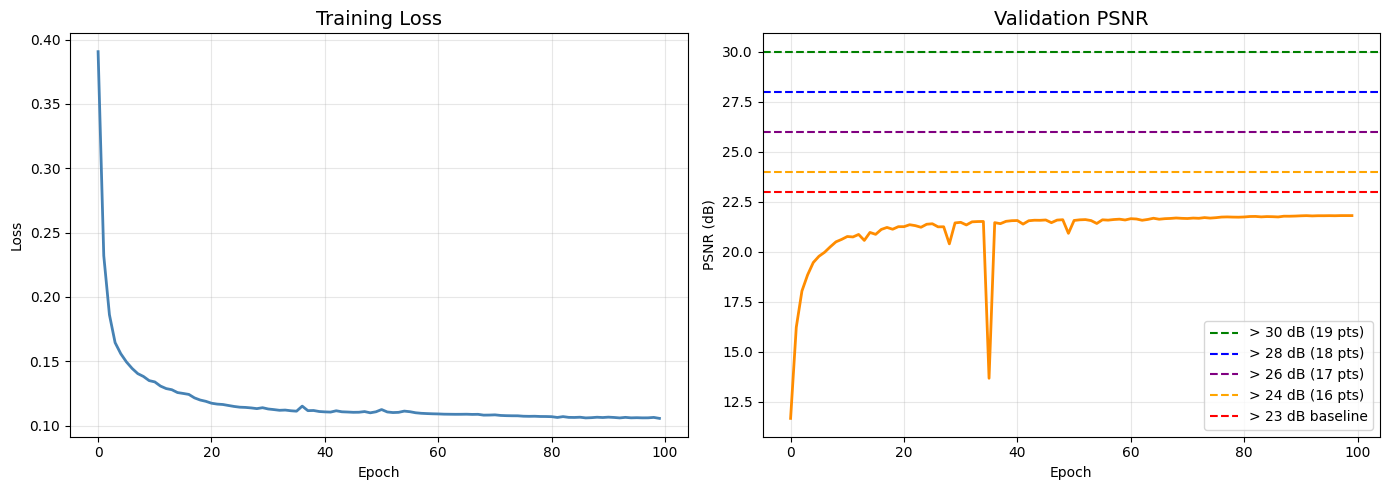

Saved to Drive!


In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(train_losses, color='steelblue', linewidth=2)
ax1.set_title('Training Loss', fontsize=14)
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.grid(True, alpha=0.3)

ax2.plot(val_psnrs, color='darkorange', linewidth=2)
ax2.axhline(y=30, color='green',  linestyle='--', label='> 30 dB (19 pts)')
ax2.axhline(y=28, color='blue',   linestyle='--', label='> 28 dB (18 pts)')
ax2.axhline(y=26, color='purple', linestyle='--', label='> 26 dB (17 pts)')
ax2.axhline(y=24, color='orange', linestyle='--', label='> 24 dB (16 pts)')
ax2.axhline(y=23, color='red',    linestyle='--', label='> 23 dB baseline')
ax2.set_title('Validation PSNR', fontsize=14)
ax2.set_xlabel('Epoch')
ax2.set_ylabel('PSNR (dB)')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'training_curves.png'), dpi=150)
plt.show()
print('Saved to Drive!')

## Cell 16: Visualize Predictions

Best model: Epoch 99 | PSNR: 21.81 dB


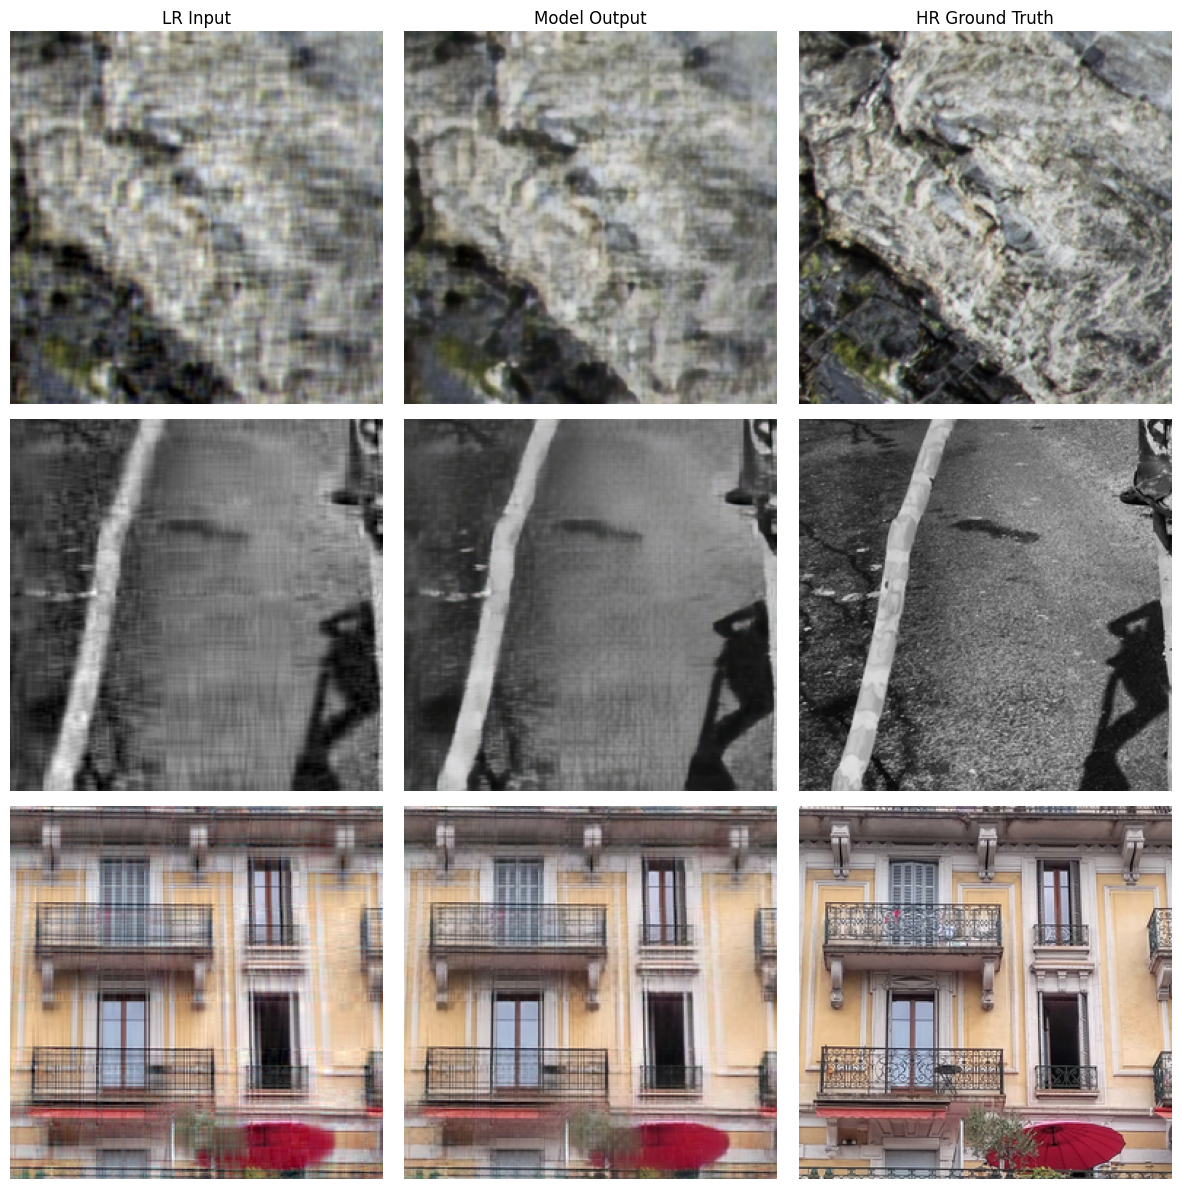

Predictions saved!


In [16]:
checkpoint = torch.load(
    os.path.join(SAVE_DIR, 'best_model.pth'),
    map_location=DEVICE
)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()
print(f'Best model: Epoch {checkpoint["epoch"]} | PSNR: {checkpoint["best_psnr"]:.2f} dB')

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
axes[0,0].set_title('LR Input',        fontsize=12)
axes[0,1].set_title('Model Output',    fontsize=12)
axes[0,2].set_title('HR Ground Truth', fontsize=12)

lr_batch, hr_batch = next(iter(val_loader))
lr_batch = lr_batch.to(DEVICE)
hr_batch = hr_batch.to(DEVICE)

with torch.no_grad():
    pred_batch = model(lr_batch)

for i in range(3):
    lr_np   = lr_batch[i].cpu().permute(1,2,0).numpy().clip(0,1)
    pred_np = pred_batch[i].cpu().permute(1,2,0).numpy().clip(0,1)
    hr_np   = hr_batch[i].cpu().permute(1,2,0).numpy().clip(0,1)
    psnr_v  = compute_psnr(pred_batch[i], hr_batch[i])

    axes[i,0].imshow(lr_np);   axes[i,0].axis('off')
    axes[i,1].imshow(pred_np); axes[i,1].set_xlabel(f'PSNR: {psnr_v:.2f} dB'); axes[i,1].axis('off')
    axes[i,2].imshow(hr_np);   axes[i,2].axis('off')

plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'sample_predictions.png'), dpi=150)
plt.show()
print('Predictions saved!')

## Cell 17: Save Calibration Images
> Professor Tip 5: Diverse calibration from all 5 zips

In [17]:
CALIB_DIR = os.path.join(SAVE_DIR, 'calibration_images')
os.makedirs(CALIB_DIR, exist_ok=True)

NUM_CALIB_PER_ZIP = 10
calib_count = 0

for lr_dir in lr_train_dirs:
    files = sorted([
        f for f in glob(os.path.join(lr_dir, '**', '*'), recursive=True)
        if f.lower().endswith(('.png', '.jpg', '.jpeg'))
    ])
    step     = max(1, len(files) // NUM_CALIB_PER_ZIP)
    selected = files[::step][:NUM_CALIB_PER_ZIP]

    for f in selected:
        img = Image.open(f).convert('RGB')
        img = img.resize((256, 256), Image.BILINEAR)
        img.save(os.path.join(CALIB_DIR, f'calib_{calib_count:03d}.jpg'))
        calib_count += 1

print(f'Saved {calib_count} diverse calibration images')
print(f'From all 5 LR training zips')
print(f'Location: {CALIB_DIR}')

Saved 50 diverse calibration images
From all 5 LR training zips
Location: /content/drive/MyDrive/Deep Learning Lab2/outputs/calibration_images


## Cell 18: Export Final ONNX — Single File
> Based on step_1_model_saving.py
> Exports as single .onnx file (not split)

In [18]:
import onnx
import shutil

# Load best model
checkpoint = torch.load(
    os.path.join(SAVE_DIR, 'best_model.pth'),
    map_location=DEVICE
)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()
print(f'Loaded: Epoch {checkpoint["epoch"]} | PSNR: {checkpoint["best_psnr"]:.2f} dB')

# Export to local first
LOCAL_ONNX  = '/content/sr_model.onnx'
dummy_input = torch.randn(1, 3, 256, 256).to(DEVICE)

torch.onnx.export(
    model,
    dummy_input,
    LOCAL_ONNX,
    export_params=True,
    opset_version=11,
    do_constant_folding=True,
    input_names=['image'],
    output_names=['predictions'],
    dynamic_axes={
        'image'      : {0: 'batch_size'},
        'predictions': {0: 'batch_size'}
    },
    verbose=False
)

# Force single file (no external .data file)
onnx_model = onnx.load(LOCAL_ONNX)
onnx.save_model(
    onnx_model,
    LOCAL_ONNX,
    save_as_external_data=False
)

# Verify
onnx.checker.check_model(onnx.load(LOCAL_ONNX))
size_mb = os.path.getsize(LOCAL_ONNX) / 1e6
print(f'ONNX size  : {size_mb:.1f} MB')
print(f'Single file: {" Yes" if size_mb > 1 else " Still split"}')

# Copy to Drive
DRIVE_ONNX = os.path.join(SAVE_DIR, 'sr_model.onnx')
shutil.copy2(LOCAL_ONNX, DRIVE_ONNX)
print(f'Saved to Drive: {DRIVE_ONNX} ')

/tmp/ipykernel_864/1675552791.py:17: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(
W0404 20:09:59.861000 864 torch/onnx/_internal/exporter/_compat.py:125] Setting ONNX exporter to use operator set version 18 because the requested opset_version 11 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features


Loaded: Epoch 99 | PSNR: 21.81 dB


W0404 20:10:00.375000 864 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'input' from (input, boxes, output_size: 'Sequence[int]', spatial_scale: 'float' = 1.0, sampling_ratio: 'int' = -1, aligned: 'bool' = False). Treating as an Input.
W0404 20:10:00.376000 864 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'boxes' from (input, boxes, output_size: 'Sequence[int]', spatial_scale: 'float' = 1.0, sampling_ratio: 'int' = -1, aligned: 'bool' = False). Treating as an Input.
W0404 20:10:00.378000 864 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'input' from (input, boxes, output_size: 'Sequence[int]', spatial_scale: 'float' = 1.0). Treating as an Input.
W0404 20:10:00.380000 864 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'boxes' from (input, boxes, output_size: 'Sequence[int]', spatial_scale: 'float' = 1.0). Treating as an Input.
/usr/lib/python3.12/copyre

Applied 82 of general pattern rewrite rules.
ONNX size  : 13.2 MB
Single file:  Yes
Saved to Drive: /content/drive/MyDrive/Deep Learning Lab2/outputs/sr_model.onnx 


## Cell 19: Final Summary

In [19]:
total_params = sum(p.numel() for p in model.parameters())
onnx_size_mb = os.path.getsize(LOCAL_ONNX) / 1e6

print('=' * 65)
print('LAB 2 — COMPLETE!')
print('=' * 65)
print(f'Architecture         : LightResUNet (base_ch=16)')
print(f'Total Parameters     : {total_params:,}')
print(f'Best Validation PSNR : {best_psnr:.2f} dB')
print(f'ONNX file size       : {onnx_size_mb:.1f} MB')
print(f'Best model (.pth)    : {SAVE_DIR}/best_model.pth')
print(f'ONNX model           : {SAVE_DIR}/sr_model.onnx')
print(f'Calibration images   : {CALIB_DIR}')
print()
print('CANVAS SUBMISSION CHECKLIST:')
print('   training_script.py')
print('   onnx_to_mxq_script.py')
print('   sr_model.mxq')
print('   best_model.pth')
print()
print('NEXT STEPS (NPU Lab):')
print('  1. Download sr_model.onnx from Drive')
print('  2. Download calibration_images/ from Drive')
print('  3. Run step_2 → .onnx to .mxq')
print('  4. Run step_3 → get PSNR on NPU')
print('  5. Submit on Canvas before April 8th!')
print('=' * 65)

LAB 2 — COMPLETE!
Architecture         : LightResUNet (base_ch=16)
Total Parameters     : 3,237,831
Best Validation PSNR : 21.81 dB
ONNX file size       : 13.2 MB
Best model (.pth)    : /content/drive/MyDrive/Deep Learning Lab2/outputs/best_model.pth
ONNX model           : /content/drive/MyDrive/Deep Learning Lab2/outputs/sr_model.onnx
Calibration images   : /content/drive/MyDrive/Deep Learning Lab2/outputs/calibration_images

CANVAS SUBMISSION CHECKLIST:
   training_script.py
   onnx_to_mxq_script.py
   sr_model.mxq
   best_model.pth

NEXT STEPS (NPU Lab):
  1. Download sr_model.onnx from Drive
  2. Download calibration_images/ from Drive
  3. Run step_2 → .onnx to .mxq
  4. Run step_3 → get PSNR on NPU
  5. Submit on Canvas before April 8th!
